In [221]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn .linear_model  import Perceptron
from sklearn.metrics import accuracy_score, classification_report,  confusion_matrix
from tensorflow.keras.models import  Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import  Flatten
from tensorflow.keras.layers import MaxPooling2D

In [188]:
df=pd.read_csv("mnist.csv")

In [189]:
df.shape

(42000, 785)

In [190]:
# Check for missing values and general dataset info
print("Missing values summary:", df.isnull().sum().sum())
display(df.head())

Missing values summary: 0


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [191]:
# 1. Handle missing values by dropping rows with NaN
df_cleaned = df.dropna().copy()

In [192]:
df_cleaned.dtypes

,0
label,int64
pixel0,int64
pixel1,int64
pixel2,int64
pixel3,int64
...,...
pixel779,int64
pixel780,int64
pixel781,int64
pixel782,int64


In [193]:
# Separate the dataset into features (X) and target labels (y)
y = df_cleaned['label'].astype(int)
X = df_cleaned.drop(columns=['label'])

print("Features (X) shape:", X.shape)
print("Target labels (y) shape:", y.shape)

Features (X) shape: (42000, 784)
Target labels (y) shape: (42000,)


In [194]:
#Train test Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [195]:
# X_train ,  X_test data  convert them  into  range between  (1-0)
X_train  = X_train.astype('float32')/255
X_test = X_test.astype('float32')/255

In [196]:
# X_train,  X_test  date reshape to image  pixels  and  array
X_train_img = X_train.values.reshape(-1,28,28)
X_test_img = X_test.values.reshape(-1,28,28)

In [197]:
y_train_cat= to_categorical(y_train,10)
y_test_cat= to_categorical(y_test,10)

In [235]:
Perceptron= Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(10, activation="softmax")
])

In [236]:
Perceptron.compile(optimizer="sgd",
                   loss="categorical_crossentropy",
                   metrics=["accuracy"])

In [237]:
history_percp=Perceptron.fit(X_train_img,
                             y_train_cat,
                             epochs=5,
                             batch_size=32,
                             validation_data=(X_test_img, y_test_cat),
                             verbose=1)

Epoch 1/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7815 - loss: 0.9456 - val_accuracy: 0.8582 - val_loss: 0.6036
Epoch 2/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8680 - loss: 0.5309 - val_accuracy: 0.8758 - val_loss: 0.4865
Epoch 3/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8815 - loss: 0.4546 - val_accuracy: 0.8842 - val_loss: 0.4389
Epoch 4/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8888 - loss: 0.4172 - val_accuracy: 0.8871 - val_loss: 0.4126
Epoch 5/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8940 - loss: 0.3939 - val_accuracy: 0.8924 - val_loss: 0.3950


In [238]:
acc_perp=Perceptron.evaluate(X_test_img, y_test_cat,verbose=0)[1]

In [239]:
acc_perp

0.892380952835083

In [203]:
ann=Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation="relu"),
    Dense(64,  activation="relu"),
    Dense(10, activation="softmax"),
])

In [204]:
ann.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [205]:
hostory_ann=ann.fit(X_train_img, y_train_cat, epochs=10, batch_size=32, validation_data=(X_test_img,y_test_cat),verbose=1)

Epoch 1/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9079 - loss: 0.3125 - val_accuracy: 0.9482 - val_loss: 0.1730
Epoch 2/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9601 - loss: 0.1292 - val_accuracy: 0.9623 - val_loss: 0.1248
Epoch 3/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9731 - loss: 0.0883 - val_accuracy: 0.9625 - val_loss: 0.1249
Epoch 4/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9804 - loss: 0.0633 - val_accuracy: 0.9644 - val_loss: 0.1175
Epoch 5/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9841 - loss: 0.0476 - val_accuracy: 0.9690 - val_loss: 0.1128
Epoch 6/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9878 - loss: 0.0373 - val_accuracy: 0.9685 - val_loss: 0.1152
Epoch 7/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9895 - loss: 0.0310 - val_accuracy: 0.9681 - val_loss: 0.1110
Epoch 8/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9919 - loss: 0.0244 - 

In [206]:
acc_ann=ann.evaluate(X_test_img,y_test_cat, verbose=0)[1]

In [207]:
acc_ann

0.9713095426559448

In [209]:
X_train_cnn=X_train.values.reshape(-1,28,28,1)
X_test_cnn=X_test.values.reshape(-1,28,28,1)

In [222]:
cnn=Sequential([
    Conv2D(32, kernel_size=(3,3), activation="relu",input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),\
    Conv2D(64, kernel_size=(3,3), activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128,  activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax"),


])

In [223]:
cnn.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [224]:
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=5,
    batch_size=32,
    validation_data=(X_test_cnn, y_test_cat),
    verbose=1
)

acc_cnn = cnn.evaluate(X_test_cnn, y_test_cat, verbose=0)[1]

print("CNN Test Accuracy:", acc_cnn)

Epoch 1/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 38s 34ms/step - accuracy: 0.9129 - loss: 0.2808 - val_accuracy: 0.9776 - val_loss: 0.0714
Epoch 2/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.9714 - loss: 0.0984 - val_accuracy: 0.9842 - val_loss: 0.0532
Epoch 3/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 40s 33ms/step - accuracy: 0.9776 - loss: 0.0752 - val_accuracy: 0.9861 - val_loss: 0.0436
Epoch 4/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 36s 34ms/step - accuracy: 0.9813 - loss: 0.0603 - val_accuracy: 0.9863 - val_loss: 0.0430
Epoch 5/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 34s 32ms/step - accuracy: 0.9853 - loss: 0.0489 - val_accuracy: 0.9892 - val_loss: 0.0344
CNN Test Accuracy: 0.9891666769981384


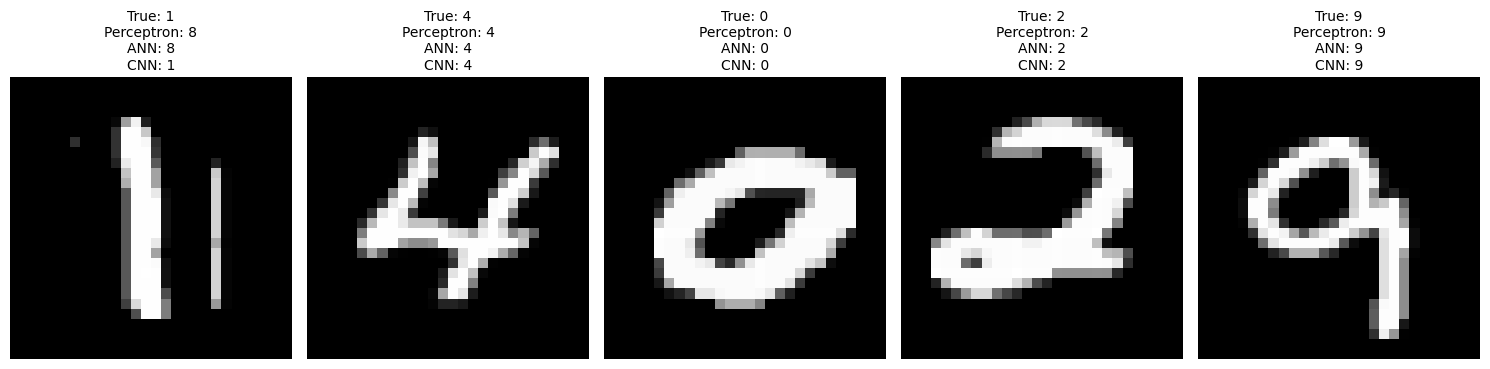

In [257]:
import random
import numpy as np
import matplotlib.pyplot as plt

# 1. Select 5 random indices from the test set without a fixed seed
random_indices = random.sample(range(len(X_test_img)), 5)

# 2. Get the images and true labels
sample_images = X_test_img[random_indices]
sample_labels = y_test.iloc[random_indices].values

# 3. Prepare inputs for each model
sample_images_percep = sample_images.reshape(-1, 28, 28)      # Perceptron (Keras) expects (N, 28, 28)
sample_images_ann    = sample_images.reshape(-1, 28, 28)      # ANN (Keras) — adjust if it expects flat (N, 784)
sample_images_cnn    = sample_images.reshape(-1, 28, 28, 1)   # CNN expects (N, 28, 28, 1)

# 4. Predict
pred_percep = Perceptron.predict(sample_images_percep, verbose=0).argmax(axis=1)
pred_ann    = ann.predict(sample_images_ann, verbose=0).argmax(axis=1)
pred_cnn    = cnn.predict(sample_images_cnn, verbose=0).argmax(axis=1)

# 5. Plot
fig, axes = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    axes[i].imshow(sample_images[i], cmap='gray')
    axes[i].axis('off')
    axes[i].set_title(
        f"True: {sample_labels[i]}\n"
        f"Perceptron: {pred_percep[i]}\n"
        f"ANN: {pred_ann[i]}\n"
        f"CNN: {pred_cnn[i]}",
        fontsize=10
    )

plt.tight_layout()
plt.show()